<a href="https://colab.research.google.com/github/fddxxueyj/SINDy-ENSO-Recharge-Discharge-Model/blob/main/FourierDelaySINDy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [128]:
import numpy as np
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt

In [129]:
# 1. Noisy Mackey-Glass SDDE (process noise)
rng = np.random.default_rng(7)
dt, tau_true = 0.1, 17.0
sigma = 0.008  # Process noise intensity

t = np.arange(0, 600.0 + dt/2, dt)

x = np.empty(len(t))
x[0] = 1.2
steps = round(tau_true/dt)

for k in range(len(t)-1):
    z = x[k-steps] if k >= steps else 1.2

    drift = -0.1*x[k] + 0.2*z/(1+z**10)
    noise = sigma*np.sqrt(dt)*rng.normal()

    x[k+1] = x[k] + dt*drift + noise

# No observation noise
x_obs = x.copy()

xs = savgol_filter(x_obs, 51, 3)
y = savgol_filter(x_obs, 51, 3, deriv=1, delta=dt)

fit = slice(250, -250)
y = y[fit]
t = t[fit]



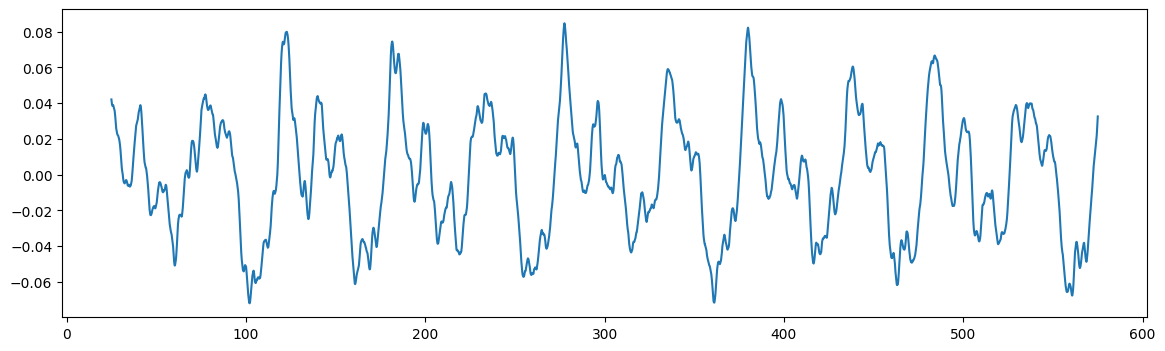

In [130]:
plt.figure(figsize=(14, 4))
plt.plot(t, y)

In [131]:
# 2. Fourier delay operator
ext = np.r_[xs, xs[-2:0:-1]]
w = 2*np.pi*np.fft.rfftfreq(len(ext), dt)
X = np.fft.rfft(ext)

mask = (w <= 2*np.pi/2.0).astype(float)
mask[-1] = 0.0

def fit_at(tau, support=None):
    phase = X*mask*np.exp(-1j*w*tau)

    z = np.fft.irfft(phase, n=len(ext))[:len(x)][fit]
    dz = np.fft.irfft(-1j*w*phase, n=len(ext))[:len(x)][fit]

    h = z/(1+z**10)
    dh = (1-9*z**10)/(1+z**10)**2 * dz

    xx = xs[fit]
    A = np.column_stack([
        np.ones_like(xx), xx, xx**2, xx**3, h
    ])

    if support is None:
        support = np.ones(A.shape[1], dtype=bool)

    coef = np.zeros(A.shape[1])
    coef[support] = np.linalg.lstsq(
        A[:, support], y, rcond=None
    )[0]

    r = A@coef - y

    loss = np.mean(r**2)
    grad = 2*np.mean(r*coef[-1]*dh)

    return loss, grad, coef, A



In [132]:
# 3. Adam gradient descent
def adam_delay(tau, support=None, lr=0.08, iters=300):
    m = v = 0.0

    for k in range(1, iters+1):
        _, g, _, _ = fit_at(tau, support)

        m = 0.9*m + 0.1*g
        v = 0.999*v + 0.001*g*g

        tau -= lr*(m/(1-0.9**k)) / (
            np.sqrt(v/(1-0.999**k)) + 1e-12
        )
        # tau = np.clip(tau, 12.0, 22.0)

    return float(tau)

rng = np.random.default_rng(42)

best_loss = np.inf
best_tau = None

# Multiple random initializations
for i in range(10):
    tau0 = rng.uniform(1.0, 50.0)

    tau_candidate = adam_delay(tau0)
    loss, _, _, _ = fit_at(tau_candidate)

    if loss < best_loss:
        best_loss = loss
        best_tau = tau_candidate


tau = best_tau

# Sparse support selection
_, _, _, A = fit_at(tau)
scale = np.linalg.norm(A, axis=0)
c = np.linalg.lstsq(A / scale, y, rcond=None)[0]

support = np.abs(c) > 0.1*np.max(np.abs(c))

# Sparse refinement
tau = adam_delay(tau, support)
loss, _, coef, _ = fit_at(tau, support)

print("Final delay:", tau)
print("Coefficients:", coef)
print("MSE:", loss)

Final delay: 17.06467547381791
Coefficients: [ 0.         -0.10236813  0.00134623  0.          0.20161307]
MSE: 3.587935722847831e-05


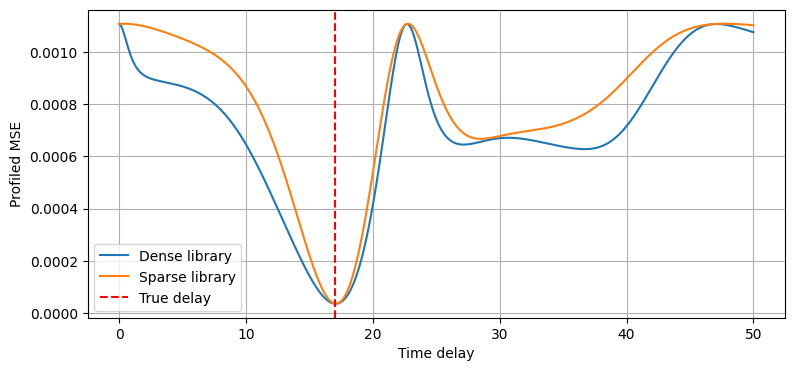

In [133]:
tau_grid = np.linspace(0, 50, 501)

support_true = np.array([
    False, True, False, False, True
])

L_dense = [fit_at(tau)[0] for tau in tau_grid]

L_sparse = [
    fit_at(tau, support_true)[0]
    for tau in tau_grid
]

plt.figure(figsize=(9, 4))

plt.plot(tau_grid, L_dense, label="Dense library")
plt.plot(tau_grid, L_sparse, label="Sparse library")

plt.axvline(17, color="red", ls="--", label="True delay")

plt.xlabel("Time delay")
plt.ylabel("Profiled MSE")
plt.legend()
plt.grid()
plt.show()